In [7]:
import os
import pandas as pd
import numpy as np
import torch
from scipy.sparse import save_npz, load_npz, csr_matrix
from scipy.ndimage import gaussian_filter1d
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib



plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import random
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
plt.rcParams["axes.grid"] = False
from sklearn.manifold import TSNE
matplotlib.rcParams['axes.linewidth'] = .5
from scipy.sparse import save_npz, load_npz, csr_matrix

In [8]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [15]:
df_list = []
for filename in os.listdir('Results'):
    f = os.path.join('Results', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
df = pd.concat(df_list,ignore_index=True)

df= df[df.n_neurons>=50]
df = df[df.pca_1>.5]

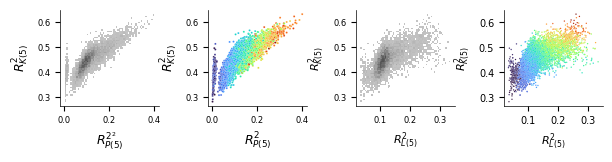

In [16]:
fig = plt.figure(figsize=(7,1.25))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,4,wspace=.5)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[0,3])
#df.pca_error = np.log(df.pca_error)

sns.histplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,alpha = 1,legend= False, color='gray')
# sns.regplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})
#sns.regplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})


sns.scatterplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax1,alpha = 1,s=2, hue = 'linear_error_train_mean',legend=False,palette = 'turbo')
# sns.regplot(data = df,x = 'linear_error_train',y='kmeans_error',ax=ax1,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})

sns.histplot(data = df,x = 'linear_error_train_mean',y='kmeans_error',ax=ax2,alpha = 1,legend=False,color='gray')
#sns.scatterplot(data = df[df.pca_error<.1],x = 'linear_error_train',y='kmeans_error',ax=ax2,alpha = 1,s=2)
# sns.regplot(data = df[df.pca_error<.05],x = 'linear_error_train',y='kmeans_error',ax=ax2,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})

#sns.histplot(data = df[df.pca_error>.075],x = 'linear_error_train',y='kmeans_error',ax=ax3,alpha = .75,color='gray',legend=False)
#sns.histplot(data = df[df.pca_error<.075],x = 'linear_error_train',y='kmeans_error',ax=ax3,alpha = 1,legend=False)
sns.scatterplot(data = df,x = 'linear_error_train_mean',y='kmeans_error',ax=ax3,alpha = 1,s = 1,legend=False, hue = 'pca_error',palette = 'turbo')

# sns.regplot(data = df[df.pca_error<.1],x = 'linear_error_train',y='kmeans_error',ax=ax3,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})
#sns.scatterplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,alpha = 1,legend=False)


# sns.histplot(data = df[(df.relative_test_loss>0.25) ],x = 'pca_error',y='kmeans_error',ax=ax1,alpha = 1,bins=35,cbar=True)
# sns.histplot(data = df[(df.relative_test_loss>0.5)   ],x = 'pca_error',y='kmeans_error',ax=ax2,alpha = 1,bins=35,cbar=True)
# sns.histplot(data = df[df.relative_test_loss>0.75],x = 'pca_error',y='kmeans_error',ax=ax3,alpha =1 ,bins=35,cbar=True)

# sns.histplot(data = df2,x = 'pca_error',y='kmeans_error',ax=ax0,alpha = 1,bins=35)
# sns.histplot(data = df2[df2.linear_error>0.3],x = 'pca_error',y='kmeans_error',ax=ax1,alpha = 1,bins=35)
# sns.histplot(data = df2[df2.linear_error>0.6],x = 'pca_error',y='kmeans_error',ax=ax2,alpha = 1,bins=35)
# sns.histplot(data = df2[df2.linear_error>0.9],x = 'pca_error',y='kmeans_error',ax=ax3,alpha = 1,bins=35)
#sns.histplot(data = df[(df.linear_error>.8)],x = 'pca_error',y='kmeans_error',alpha = .5,ax=ax2)

for ax in [ax0,ax1,ax2]:
    lims = [
            np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
            np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
        ]
    cbar = ax.figure.axes[-1]
    cbar.tick_params(labelsize=6)
    # now plot both limits against eachother
    # ax.plot(lims, lims, 'k-', alpha=0.15, zorder=0,lw=.5)
    # ax.set_aspect('equal')
    # ax.set_xlim(0,0.75)
    # ax.set_ylim(0,.75)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    #ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
    ax.xaxis.set_tick_params(labelsize=6, bottom=True)
    ax.yaxis.set_tick_params(labelsize=6, left=True)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')

ax0.set_xlabel(r"$R^{2^2}_{P(5)}$", fontsize=9)
ax0.set_ylabel(r"$R^2_{K(5)}$", fontsize=9)

ax1.set_xlabel(r"$R^2_{P(5)}$", fontsize=9)
ax1.set_ylabel(r"$R^2_{K(5)}$", fontsize=9)

ax2.set_xlabel(r"$R^2_{L(5)}$", fontsize=8)
ax2.set_ylabel(r"$R^2_{K(5)}$", fontsize=8)

ax3.set_xlabel(r"$R^2_{L(5)}$", fontsize=8)
ax3.set_ylabel(r"$R^2_{K(5)}$", fontsize=8)

ax3.spines['right'].set_visible(False)
ax3.spines['top'].set_visible(False)
ax3.spines['bottom'].set_visible(True)
ax3.spines['left'].set_visible(True)

#ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
ax3.xaxis.set_tick_params(labelsize=7, bottom=True)
ax3.yaxis.set_tick_params(labelsize=7, left=True)
ax3.spines['left'].set_color('black')
ax3.spines['bottom'].set_color('black')

plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

<Axes: xlabel='pca_error', ylabel='Count'>

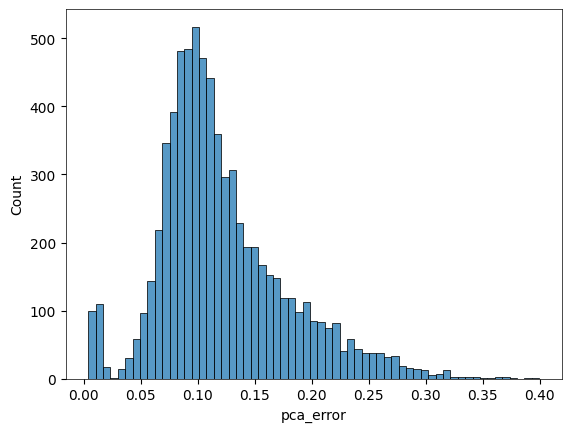

In [20]:
plt.figure()
sns.histplot(data =df , x = 'pca_error')

In [21]:
sorted_df = df[(df.pca_error<.025)].sort_values('kmeans_error',ascending=True)
sorted_df.head(25)

,eid,n_steps,sample_size,n_neurons,threshold,sigma,neurons,conditions,event,linear_error_train_mean,linear_error_train_std,linear_error_test_mean,linear_error_test_std,pca_error,pca_1,kmeans_error
8278,9fcbd1a0-77e6-4c41-9428-eeaee74becd5,100,50,79,1,10,"[38, 69, 32, 70, 21, 13, 16, 51, 76, 74, 52, 4...","[choice, side, prev_side]",response_times,0.036668,0.003443,0.294632,0.005149,0.003903,0.546329,0.282771
1169,9fcbd1a0-77e6-4c41-9428-eeaee74becd5,100,50,79,1,10,"[35, 22, 16, 5, 25, 14, 4, 55, 61, 65, 56, 66,...","[side, prev_choice, prev_side]",feedback_times,0.046673,0.016890,0.302524,0.005519,0.005025,0.506596,0.292120
4169,d901aff5-2250-467a-b4a1-0cb9729df9e2,100,50,502,1,10,"[35, 375, 23, 51, 397, 410, 440, 149, 119, 50,...","[prev_reward, choice, prev_side]",stimOn_times,0.046630,0.009507,0.318131,0.003497,0.004237,0.544082,0.305914
8750,90e524a2-aa63-47ce-b5b8-1b1941a1223a,100,50,392,1,10,"[129, 66, 218, 330, 184, 304, 163, 92, 8, 161,...","[prev_side, side]",feedback_times,0.037196,0.002459,0.319733,0.002899,0.013120,0.504479,0.310701
5922,9fcbd1a0-77e6-4c41-9428-eeaee74becd5,100,50,79,1,10,"[22, 14, 24, 45, 19, 6, 29, 26, 23, 57, 49, 37...","[reward, choice, prev_side]",feedback_times,0.047687,0.005826,0.239103,0.003078,0.003942,0.538916,0.312911
2780,bb6a5aae-2431-401d-8f6a-9fdd6de655a9,100,50,169,1,10,"[0, 95, 48, 114, 85, 119, 134, 89, 31, 118, 27...","[prev_reward, side, choice]",response_times,0.046934,0.002149,0.394143,0.004168,0.008038,0.534887,0.314109
384,9fcbd1a0-77e6-4c41-9428-eeaee74becd5,100,50,79,1,10,"[76, 17, 3, 56, 11, 21, 62, 75, 55, 67, 9, 24,...","[prev_side, side, choice]",response_times,0.038504,0.000567,0.255353,0.002267,0.005820,0.554104,0.319634
6291,72982282-e493-45ee-87ce-aa45cb3a3ec1,100,50,287,1,10,"[48, 33, 68, 8, 93, 238, 275, 22, 206, 30, 263...","[prev_choice, choice, prev_side]",stimOn_times,0.055214,0.013634,0.349060,0.002610,0.008374,0.546628,0.323020
6525,9fcbd1a0-77e6-4c41-9428-eeaee74becd5,100,50,79,1,10,"[35, 26, 58, 5, 16, 3, 61, 51, 32, 9, 18, 66, ...","[prev_reward, side, prev_choice]",response_times,0.039249,0.003030,0.246685,0.002878,0.006488,0.511969,0.326032
1927,bb6a5aae-2431-401d-8f6a-9fdd6de655a9,100,50,169,1,10,"[47, 48, 4, 79, 121, 67, 136, 107, 163, 53, 11...","[prev_choice, prev_side, choice]",feedback_times,0.057880,0.007187,0.342250,0.004351,0.006137,0.543584,0.327808


In [1]:
sns.color_palette('coolwarm')

NameError: name 'sns' is not defined

In [ ]:
sns.p

In [6]:
from bwm_functions import get_aligned_response_matrix, compute_kmeans_error, LinearNet

In [709]:

# eid = random.choice(eids)
#
#eid = sorted_df['eid'].values[row]
row = 12
eid = sorted_df['eid'].values[row]

full_path_to_random_folder = os.path.join("Data", eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 300
sigma = 5
latent_dim = 25
hidden_dim = 30
n_steps = 100

threshold = 5
min_trials_per_condition  = 100
# Check if any folders were found

event = sorted_df.event.values[row]
conditions = sorted_df.conditions.values[row]
neuron_indices = sorted_df.neurons.values[row]
#conditions = ["choice","side"]
# Construct the full path to the randomly selected folder

clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')


spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

#  responses = get_aligned_response_matrix(spikes, trials[event],stride=.005, step=.005, n_steps=100,sigma = 10)


Randomly selected eid: Data/a7763417-e0d6-4f2a-aa55-e382fd9b5fb8


In [710]:

from bwm_functions import *

# shape n_pseudo x n_conditions x time x n
response_matrix_train,condition_matrix_train, response_matrix_test, condition_matrix_test = get_aligned_response_matrix(spikes, clusters, trials, event, conditions, stride=.005, step=.005,
                                            n_steps=n_steps,sigma = sigma, threshold = threshold, min_trials_per_condition = min_trials_per_condition)


print(response_matrix_test.shape)


n_neurons  = response_matrix_train.shape[3]
print(n_neurons)
#neuron_indices = np.random.choice(n_neurons, sample_size, replace=False)
#response_matrix_test = response_matrix_test[:, :,:, neuron_indices]
#response_matrix_train = response_matrix_train[:, :,:, neuron_indices]


# Z-score single neuron responses
response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2), keepdims=True)) / np.std(response_matrix_train, axis=(0, 1, 2), keepdims=True)
response_matrix_test = (response_matrix_test - np.mean(response_matrix_test, axis=(0, 1, 2), keepdims=True)) / np.std(response_matrix_test, axis=(0, 1, 2), keepdims=True)
#     responses_test = (responses_test - np.mean(responses_test, axis=(0, 1), keepdims=True)) / np.std(responses_test, axis=(0, 1),
#                                                                                       keepdims=True)
#     mean_responses_test = (mean_responses_test - np.mean(mean_responses_test, axis=(0, 1), keepdims=True)) / np.std(
#         mean_responses_test, axis=(0, 1), keepdims=True)
# #
mean_responses_train = np.mean(response_matrix_train, axis=0, keepdims=True)
# pca_error = compute_pca_error(mean_responses_train.reshape(-1, mean_responses_train.shape[2]), dim)
pca = PCA().fit(mean_responses_train.reshape(-1, mean_responses_train.shape[2]))
pca_error =  np.sum(pca.explained_variance_ratio_[dim:])
pca_1 = np.sum(pca.explained_variance_ratio_[1:])


kmeans_error = compute_kmeans_error(dim, mean_responses_train.reshape(-1, mean_responses_train.shape[2]).T)

response_matrix_train = torch.tensor(response_matrix_train).float()
response_matrix_test = torch.tensor(response_matrix_test).float()
# mean_responses = torch.tensor(mean_responses).float().to(device)
condition_matrix_train = torch.tensor(condition_matrix_train).float()
condition_matrix_test = torch.tensor(condition_matrix_test).float()

# train_indices = np.random.choice(len(responses), int(.8 * responses.shape[0]), replace=False)
# test_indices = list(set(range(len(responses))) - set(train_indices))
# test_indices = train_indices
y_train = response_matrix_train.reshape(-1,response_matrix_train.shape[2],response_matrix_train.shape[3])
y_test = response_matrix_test.reshape(-1,response_matrix_train.shape[2],response_matrix_train.shape[3])
condition_train = condition_matrix_train.reshape(-1,condition_matrix_train.shape[2])
condition_test = condition_matrix_test.reshape(-1,condition_matrix_train.shape[2])

# Fit Linear model
linear_model = LinearNet(n=y_train.shape[2], latent_dim=latent_dim, hidden_dim = hidden_dim, n_conditions = condition_train.shape[1])
linear_model.fit(steps=y_train.shape[1], epochs=1000, batch_size=100, lr=.01, verbose=True,
                 weight_decay=0., y_train=y_train,
                 y_test=y_test,conditions_train = condition_train, conditions_test = condition_test)
# linear_test_loss = linear_model.evaluate(condition_test,y_test, y_test.shape[1])
test_linear_loss = linear_model.evaluate( condition_test,y_test, n_steps)
train_linear_loss = linear_model.evaluate(  condition_train,y_train,n_steps)

(500, 3, 100, 543)
543
Epoch: 100/1000............. loss: 0.7648 val_loss: 0.9149
Epoch: 200/1000............. loss: 0.7532 val_loss: 0.9224
Epoch: 300/1000............. loss: 0.7401 val_loss: 0.9332
Epoch: 400/1000............. loss: 0.7365 val_loss: 0.9321
Epoch: 500/1000............. loss: 0.7322 val_loss: 0.9571


KeyboardInterrupt: 

In [711]:
x = linear_model.forward(condition_train, 100)
x = linear_model.observation_layer(x[:,:,:linear_model.latent_dim])


In [712]:
s = torch.sum((x - y_train) ** 2, dim=[0, 1]) / torch.sum((y_train) ** 2, dim=[0, 1])


In [713]:
s.shape

torch.Size([543])

In [714]:
mean_responses = torch.mean(response_matrix_train, dim=0)
mean_conditions = torch.mean(condition_matrix_train, dim=0)
linear_model.evaluate(mean_conditions, mean_responses, 100)


tensor(0.3213, grad_fn=<MeanBackward0>)

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_39085/1996968211.py:32: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_39085/1996968211.py:32: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_39085/1996968211.py:32: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])


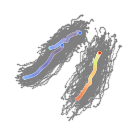

In [715]:

pca = PCA().fit(response_matrix_train.reshape(-1,response_matrix_train.shape[3]))
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
#
for i in range(100):
    for j in range(response_matrix_train.shape[1]):
        trajectory = pca.transform(response_matrix_train[i,j,:])
        sns.scatterplot(x=trajectory[:,0], y=trajectory[:,1], color='gray',alpha = .5,lw=0,ax=ax,s=1)
#
# for i in range(condition_matrix_train.shape[1]):
#
#     trajectory = pca.transform(torch.mean(response_matrix_train[:,i,:,],axis=0))
#     ax.plot(trajectory[:,0], trajectory[:,1], color='k',alpha = .5,lw=.5)
    #
# for condition in range(mean_responses_train.shape[0]):
#     trajectory = pca.transform(mean_responses_train[condition,:])
#     ax.plot(trajectory[:,0], trajectory[:,1],lw=.5,alpha = .5)

# predictions = linear_model.observation_layer(linear_model(mean_conditions, 100)[:,:,:latent_dim]).detach().numpy()
# for i in range(condition_matrix_train.shape[1]):
#     trajectory = pca.transform(predictions[i,:,:])
#     ax.plot(trajectory[:,0], trajectory[:,1],alpha = .5,lw=.5,color='red')
mean_responses = torch.mean(response_matrix_train,axis=0)
rows = []
for condition in range(mean_responses.shape[0]):
    trajectory = mean_responses[condition,:]
    predicted_trajectory = linear_model.observation_layer(linear_model(mean_conditions[None,condition,:], 100)[:,:,:latent_dim]).detach().numpy().squeeze()
    proj_trajectory = pca.transform(trajectory)
    for t in range(mean_responses.shape[1]):
        d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
        rows.append({"condition": condition,
                     't':t,
                     'x': proj_trajectory[t,0],
                     'y': proj_trajectory[t,1],
                     'd':d})
sns.scatterplot(data = pd.DataFrame(rows),x = 'x',y='y',hue = 'd',s=5,ax = ax,legend=False,palette = 'turbo')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [716]:
mean_responses = torch.mean(response_matrix_train,axis=0)
rows = []
for condition in range(mean_responses.shape[0]):
    trajectory = mean_responses[condition,:]
    predicted_trajectory = linear_model.observation_layer(linear_model(mean_conditions[None,condition,:], 100)[:,:,:latent_dim]).detach().numpy().squeeze()
    proj_trajectory = pca.transform(trajectory)
    for t in range(mean_responses.shape[1]):
        d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
        rows.append({"condition": condition,
                     't':t,
                     'x': proj_trajectory[t,0],
                     'y': proj_trajectory[t,1],
                     'd':d})

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_39085/1427675835.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_39085/1427675835.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_39085/1427675835.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = np.linalg.norm(trajectory[t,:] - predicted_trajectory[t,:])


<Axes: xlabel='x', ylabel='y'>

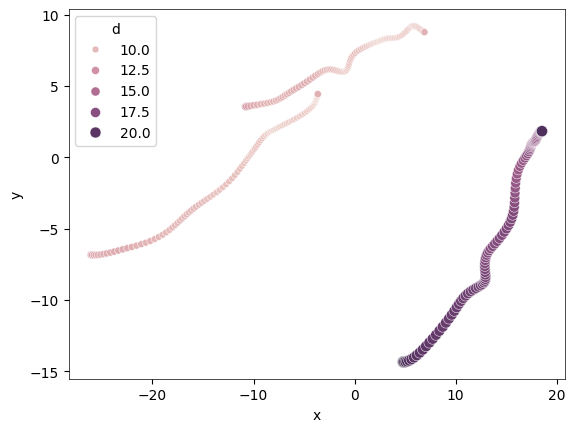

In [717]:
new_df = pd
plt.figure()
sns.scatterplot(data = pd.DataFrame(rows),x = 'x',y='y',hue = 'd',size= 'd')

In [718]:
predictions.shape

(1500, 100, 414)

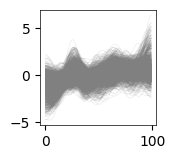

In [719]:
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
neuron = 6
for i in range(response_matrix_train.shape[0]):
    for j in range(response_matrix_train.shape[1]):
        trajectory = response_matrix_train[i,j,:,neuron]
        ax.plot( trajectory, color='gray',alpha = .15,lw=.5)


In [720]:
predictions = linear_model.observation_layer(linear_model(condition_train, 100)[:,:,:25]).detach().numpy()

In [721]:
predictions.shape

(1500, 100, 543)

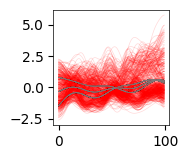

In [722]:
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
neuron = 0
for i in range(response_matrix_train.shape[0]):
        trajectory = predictions[i,:,neuron]
        ax.plot( trajectory, color='gray',alpha = .15,lw=.5)

        trajectory = y_train[i,:,neuron]
        ax.plot( trajectory, color='red',alpha = .15,lw=.5)

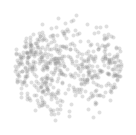

In [723]:

fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])



# kmeans= KMeans(n_clusters = 5)
# kmeans.fit(x_proj)
#
x_proj = x_proj[:]
responses = torch.mean(response_matrix_train, dim=0).reshape(-1,response_matrix_train.shape[3]).T
pca = PCA(n_components = 3)
x_proj = pca.fit_transform(responses)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1], color='gray', alpha = .25,s=8,ax=ax,legend = False,lw = 0)


# Transform the test data using the fitted model
#X_test_lda = lda.transform(X_test)

#ax.scatter(centers[:,0], centers[:,1], alpha = 1,s=3)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [724]:
x.shape

torch.Size([1500, 100, 543])

<Axes: xlabel='None', ylabel='Count'>

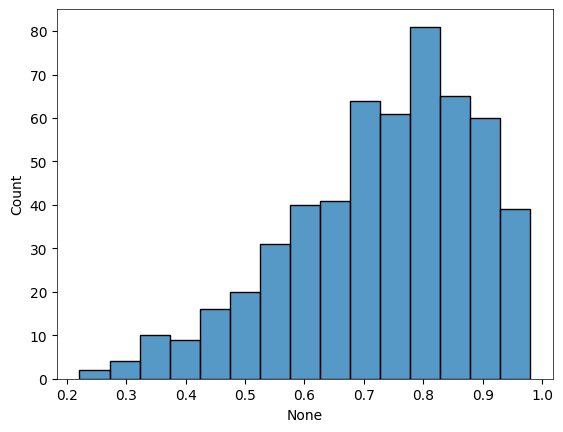

In [725]:
plt.figure()
sns.histplot(x = s.detach())

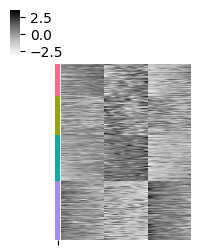

In [726]:
clustering = KMeans(n_clusters=4,n_init=20).fit(responses)

labels  = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort,:]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)),row_cluster=False, col_cluster=False, row_colors=row_colors,figsize=(2,2.5), xticklabels=False, yticklabels=False,center=0,cmap='Greys')
g.savefig('/Users/cl1704/PycharmProjects/Clustering/Figures/MainFig_2_c.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)

In [727]:

plt.figure(figsize=(1.5,.25))
sns.heatmap(mean_responses_train[:,:,3],center=0,cmap='Grays',xticklabels=False,yticklabels=False,cbar = False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

ValueError: Must pass 2-d input. shape=(1, 3, 543)

<Figure size 150x25 with 0 Axes>

In [ ]:
np.argwhere(kmeans.labels_==2)

In [ ]:
response_matrix = []
condition_matrix = []
for pseudo_trial in range(500):

    # Sample with replacement from each condition
    sub_df = df.groupby(conditions).sample(frac=1.0, replace=True)

    # Compute mean response for each condition
    mean_df = sub_df.groupby(conditions).response.apply(lambda x: np.mean(np.stack(x), axis=0)).reset_index()

    # Append
    response_matrix.append(np.stack(mean_df.response.values))
    condition_matrix.append(mean_df[conditions].values)
response_matrix = np.stack(response_matrix, axis=0)
condition_matrix = np.stack(condition_matrix, axis=0)

In [ ]:
condition_matrix.shape

In [ ]:
mean_df.response.values[0].shape